# Comment note-t-on un film ? Exploitation de la base de données MovieLens 32M

## Introduction et problématique

MovieLens est un service de recommandation de films géré par GroupLens Research (Université du Minnesota). Les utilisateurs y notent les films qu'ils ont vus, de 0,5 à 5 étoiles, pour recevoir des recommandations. Nous utilisons la version MovieLens 32M, publiée en octobre 2023 : 32 millions de notes, données par 200 948 utilisateurs sur 87 585 films, entre janvier 1995 et octobre 2023.
Une note semble être une mesure simple de la qualité d'un film. En pratique, elle dépend aussi de celui qui note (indulgent ou sévère, débutant ou habitué de la plateforme), du film (genre, époque de sortie) et du moment où la note est donnée. De plus, les utilisateurs ne notent pas des films tirés au hasard : ils notent ceux qu'ils ont choisi de voir, souvent des films qu'ils pensaient aimer.

### Problématique
Que mesure réellement une note sur MovieLens ? Parmi les écarts de notes observés, que doit-on attribuer au film (genre, ancienneté), que doit-on attribuer à l'utilisateur (indulgence, ancienneté sur la plateforme), et que doit-on attribuer à la façon dont les notes sont produites et sélectionnées ?

### Démarche
Après avoir téléchargé et joint les données (parties I et II), puis les avoir décrites (partie III), nous étudions deux dimensions de l'évolution des notes dans le temps : l'ancienneté de l'utilisateur sur la plateforme (partie IV-A), puis l'ancienneté du film au moment de la notation (partie IV-B). Une différence de note moyenne entre deux groupes peut venir de qui compose chaque groupe (effet de composition) ou d'un changement de notation des mêmes individus (effet de comportement). Les données sont observationnelles : nous décrivons des associations, pas des causes.

# I - MovieLens 32M : téléchargement et aperçu des données

In [ ]:
from donnees import telecharger, extraire
import os
import zipfile

import requests
import pandas as pd

URL = "https://files.grouplens.org/datasets/movielens/ml-32m.zip"
NOM_ZIP = "ml-32m.zip"
DOSSIER = "data"

In [2]:
telecharger(URL, NOM_ZIP)
extraire(NOM_ZIP, DOSSIER)

Le ZIP existe déjà, pas de nouveau téléchargement.
Contenu du ZIP : ['ml-32m/', 'ml-32m/tags.csv', 'ml-32m/links.csv', 'ml-32m/README.txt', 'ml-32m/checksums.txt', 'ml-32m/ratings.csv', 'ml-32m/movies.csv']


In [3]:
chemin = os.path.join(DOSSIER, "ml-32m")

movies = pd.read_csv(os.path.join(chemin, "movies.csv"))
tags = pd.read_csv(os.path.join(chemin, "tags.csv"))
links = pd.read_csv(os.path.join(chemin, "links.csv"))
ratings = pd.read_csv(os.path.join(chemin, "ratings.csv"))

On affiche le premier dataframe, qui comporte une clé d'identification des films (movieId), le titre ainsi que leur année, et le genre associé. 
La base de données comporte 87585 films.

In [4]:
print(movies.shape)
movies.head()

(87585, 3)


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


On affiche aussi les notes de ces films, qui vont être notre base de donnée principale. Le fichier est particulièrement volumineux (32 millions de notes). L'userId permet de voir quel utilisateur a mis quelle note, ce qui sera utile. 

In [5]:
print(ratings.shape)
ratings.head()

(32000204, 4)


,userId,movieId,rating,timestamp
0,1,17,4.0,944249077
1,1,25,1.0,944250228
2,1,29,2.0,943230976
3,1,30,5.0,944249077
4,1,32,5.0,943228858


La base de données donne aussi accès à des tags, c'est-à-dire des mots que les utilisateurs ont associé aux films. Nous choisissons de ne pas les étudier dans le cadre de ce projet.

In [6]:
print(tags.shape)
tags.head()

(2000072, 4)


,userId,movieId,tag,timestamp
0,22,26479,Kevin Kline,1583038886
1,22,79592,misogyny,1581476297
2,22,247150,acrophobia,1622483469
3,34,2174,music,1249808064
4,34,2174,weird,1249808102


Ce dataframe permet de faire des jointures avec des bases de données extérieures, en donnant la clé correspondante pour les films dans cette base et dans les bases IMDB et TMDB.

In [7]:
print(links.shape)
links.head()

(87585, 3)


,movieId,imdbId,tmdbId
0,1,114709,862.0
1,2,113497,8844.0
2,3,113228,15602.0
3,4,114885,31357.0
4,5,113041,11862.0


Ci dessous la cellule à faire tourner pour télécharger tous les packages utiles.

In [8]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# II- Création de dataframes utilisables pour l'analyse

On peut d'abord séparer l'année et le titre du film dans le dataframe movies.

In [9]:
movies_with_date = movies.copy()

# 1. on récupère l'année (4 chiffres entre parenthèses, à la fin du titre)
movies_with_date["year"] = movies_with_date["title"].str.extract(r"\((\d{4})\)\s*$", expand=False)

# 2. on enlève l'année du titre
movies_with_date["title"] = movies_with_date["title"].str.replace(r"\s*\(\d{4}\)\s*$", "", regex=True)

# 3. on convertit l'année en nombre
movies_with_date["year"] = pd.to_numeric(movies_with_date["year"])

movies_with_date

,movieId,title,genres,year
0,1,Toy Story,Adventure|Animation|Children|Comedy|Fantasy,1995.0
1,2,Jumanji,Adventure|Children|Fantasy,1995.0
2,3,Grumpier Old Men,Comedy|Romance,1995.0
3,4,Waiting to Exhale,Comedy|Drama|Romance,1995.0
4,5,Father of the Bride Part II,Comedy,1995.0
...,...,...,...,...
87580,292731,The Monroy Affaire,Drama,2022.0
87581,292737,Shelter in Solitude,Comedy|Drama,2023.0
87582,292753,Orca,Drama,2023.0
87583,292755,The Angry Breed,Drama,1968.0


Certains films n'ont pas de date, 617 sur 87 585 : 

In [10]:
movies_with_date[movies_with_date["year"].isna()]

,movieId,title,genres,year
15038,79607,"Millions Game, The (Das Millionenspiel)",Action|Drama|Sci-Fi|Thriller,NaN
18796,98063,Mona and the Time of Burning Love (Mona ja pal...,Drama,NaN
25425,123619,Terrible Joe Moran,(no genres listed),NaN
26356,125571,The Court-Martial of Jackie Robinson,(no genres listed),NaN
26381,125632,In Our Garden,(no genres listed),NaN
...,...,...,...,...
86528,288927,Fortunes,Comedy,NaN
86634,289193,The Wonderful Story of Henry Sugar,Adventure|Children|Comedy,NaN
86833,289909,Rattler,(no genres listed),NaN
87074,290775,Being Romanian: A Family Journal,(no genres listed),NaN


On exclut les films sans années, et on vérifie qu'elles ont bien été exclues. On réindexe bien les lignes aussi, sinon il y a un écart de 617 entre le nombre de lignes et le plus grand index. On peut aussi transformer les flottants en entiers maintenant qu'il n'y a plus de Na dans la colonne year.

In [11]:
movies_with_date = movies_with_date.dropna(subset=["year"]).reset_index(drop=True)
movies_with_date["year"].isna().sum()
movies_with_date["year"] = movies_with_date["year"].astype(int)


In [12]:
movies_with_date

,movieId,title,genres,year
0,1,Toy Story,Adventure|Animation|Children|Comedy|Fantasy,1995
1,2,Jumanji,Adventure|Children|Fantasy,1995
2,3,Grumpier Old Men,Comedy|Romance,1995
3,4,Waiting to Exhale,Comedy|Drama|Romance,1995
4,5,Father of the Bride Part II,Comedy,1995
...,...,...,...,...
86963,292731,The Monroy Affaire,Drama,2022
86964,292737,Shelter in Solitude,Comedy|Drama,2023
86965,292753,Orca,Drama,2023
86966,292755,The Angry Breed,Drama,1968


On peut aussi faire une jointure des notes et des films pour avoir le nom du film à côté de sa note. 
On commence par rajouter une colonne qui convertit le timestamp en heure lisible. Dans MovieLens, timestamp est un nombre de secondes écoulées depuis le 1er janvier 1970 (temps Unix).

In [13]:
ratings["date"] = pd.to_datetime(ratings["timestamp"], unit="s")
ratings.head()

,userId,movieId,rating,timestamp,date
0,1,17,4.0,944249077,1999-12-03 19:24:37
1,1,25,1.0,944250228,1999-12-03 19:43:48
2,1,29,2.0,943230976,1999-11-22 00:36:16
3,1,30,5.0,944249077,1999-12-03 19:24:37
4,1,32,5.0,943228858,1999-11-22 00:00:58


In [14]:
ratings_movies = pd.merge(ratings, movies_with_date, on='movieId', how='inner')

In [15]:
ratings_movies

,userId,movieId,rating,timestamp,date,title,genres,year
0,1,17,4.0,944249077,1999-12-03 19:24:37,Sense and Sensibility,Drama|Romance,1995
1,1,25,1.0,944250228,1999-12-03 19:43:48,Leaving Las Vegas,Drama|Romance,1995
2,1,29,2.0,943230976,1999-11-22 00:36:16,"City of Lost Children, The (Cité des enfants p...",Adventure|Drama|Fantasy|Mystery|Sci-Fi,1995
3,1,30,5.0,944249077,1999-12-03 19:24:37,Shanghai Triad (Yao a yao yao dao waipo qiao),Crime|Drama,1995
4,1,32,5.0,943228858,1999-11-22 00:00:58,Twelve Monkeys (a.k.a. 12 Monkeys),Mystery|Sci-Fi|Thriller,1995
...,...,...,...,...,...,...,...,...
31965033,200948,79702,4.5,1294412589,2011-01-07 15:03:09,Scott Pilgrim vs. the World,Action|Comedy|Fantasy|Musical|Romance,2010
31965034,200948,79796,1.0,1287216292,2010-10-16 08:04:52,Centurion,Action|Adventure|Drama|Thriller|War,2010
31965035,200948,80350,0.5,1294412671,2011-01-07 15:04:31,Vampires Suck,Comedy,2010
31965036,200948,80463,3.5,1350423800,2012-10-16 21:43:20,"Social Network, The",Drama,2010


Il y a moins de 32 millions de lignes dans cette analyse car on a exclu les films qui n'avaient pas de date de sortie.

# III - Statistiques descriptives

On regarde d’abord les années de sortie et les genres des films, puis la répartition des notes. 

### Approche sur les notes en fonction du temps, descriptive

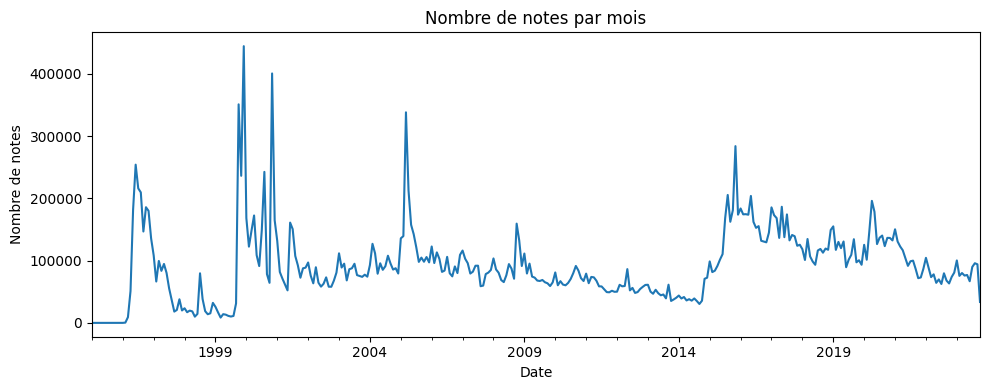

In [16]:
# Nombre de notes par mois
notes_par_mois = ratings_movies.groupby(ratings_movies["date"].dt.to_period("M")).size()

fig, ax = plt.subplots(figsize=(10, 4))
notes_par_mois.plot(ax=ax)
ax.set_title("Nombre de notes par mois")
ax.set_xlabel("Date")
ax.set_ylabel("Nombre de notes")
plt.tight_layout()
plt.show()

On observe donc des pics d'activité des utilisateurs au cours du temps, en 1996, au début des années 2000 puis qui se stabilise autour de 100 000 notes enregistrées par mois, puis il y a un regain d'activité vers 2016, puis l'activité décline lentement. Les pics d'activité correspondent probablement à des pics d'adhésion, car un utilisateur doit avoir au moins 20 notes pour être enregistré dans la database, les 20 enregistrements sont donc probablement faits le même jour. 

### Approche par date de sortie des films

In [17]:
display(movies_with_date["year"].describe())

count    86968.000000
mean      1995.354809
std         26.011029
min       1874.000000
25%       1981.000000
50%       2006.000000
75%       2015.000000
max       2023.000000
Name: year, dtype: float64

Cette sortie décrit les années de sortie dans le dataset "movies_with_year". Les films sont sortis en moyenne en 1995 mais la médiane est 2006 donc il y a majoritairement des films récents dans le dataset (qui ont environ moins de 20 ans). Le plus vieux film de la database est sorti en 1874 et le plus récent est sorti en 2023, la base de données ne va pas jusqu'à aujourd'hui mais s'arrête en 2023.

Réalisons maintenant un histogramme pour représenter ces dates de sortie de films. Le premier film est sorti en 1874 et le dernier en 2023, on réalise donc 2023-1874+1=150 bins pour que chaque trait représente une année. 

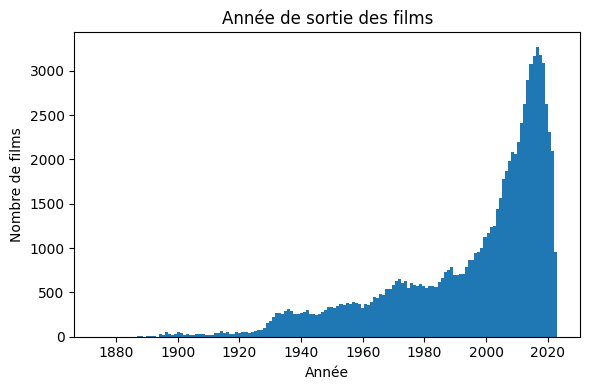

In [18]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6, 4))

movies_with_date["year"].plot(kind="hist", bins=150, ax=ax)
ax.set_title("Année de sortie des films")
ax.set_xlabel("Année")
ax.set_ylabel("Nombre de films")
plt.tight_layout()
plt.show()

On voit donc bien ici que la majorité des films du dataset sont sortis après 2000, il y a une surreprésentation des films qui sont sortis après la création de la base de données IMBd en 1990. Le nombre de films par année croît fortement à partir des années 1990 et atteint environ 3 300 vers 2016. La baisse finale (environ 950 films en 2023) vient peut-être de films récents encore peu ajoutés au catalogue : à ne pas interpréter comme un recul de la production.

### Approche par notes des films

In [19]:
display(ratings_movies["rating"].describe())
display(ratings["rating"].value_counts().sort_index())

count    3.196504e+07
mean     3.540361e+00
std      1.058993e+00
min      5.000000e-01
25%      3.000000e+00
50%      3.500000e+00
75%      4.000000e+00
max      5.000000e+00
Name: rating, dtype: float64

rating
0.5     525132
1.0     946675
1.5     531063
2.0    2028622
2.5    1685386
3.0    6054990
3.5    4290105
4.0    8367654
4.5    2974000
5.0    4596577
Name: count, dtype: int64

La note moyenne est de 3,54 (médiane 3,5). La note modale est 4,0 (8,4 millions de notes, 26 %) et 63 % des notes sont supérieures ou égales à 3,5. 

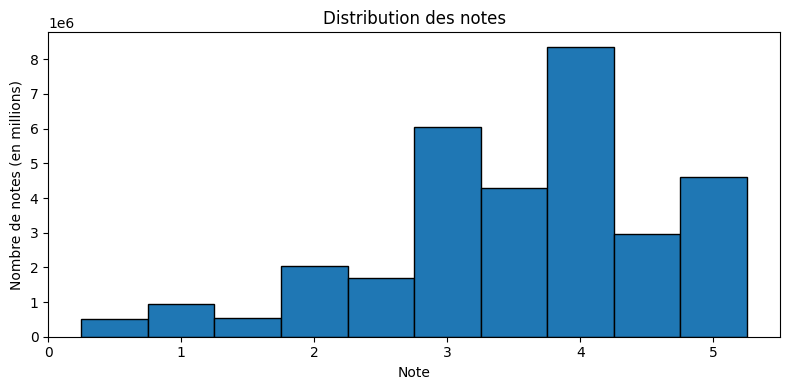

In [20]:
# Histogramme de toutes les notes
fig, ax = plt.subplots(figsize=(8, 4))
ratings_movies["rating"].plot(kind="hist", bins=[0.25 + 0.5 * i for i in range(11)], ax=ax, edgecolor="black")
ax.set_title("Distribution des notes")
ax.set_xlabel("Note")
ax.set_ylabel("Nombre de notes (en millions)")
plt.tight_layout()
plt.show()

Il y a 10 bins donc chaque rectangle est une note (0.5, 1, 1.5 ...). On peut donc voir les notes données par les utilisateurs. 4 est la note la plus donnée, suivie de 3 puis 5. On voit donc que l'on donne aux films surtout des bonnes notes, et que l'extrême positif (5) est 9 fois plus fréquent que l'extrême négatif (0,5) (4,5 millions à 0,5 millions de notes).

On observe que les notes entières sont systématiquements plus données que la note non entière supérieure et celle inférieure, on y voit peut-être là l'effet d'un biais psychologique qui fait préférer un chiffre entier à un non entier. On teste cette hypothèse sur les chiffres entiers.

In [21]:
# On regarde la part des notes non entières chaque année
demi_notes = (ratings["rating"] % 1 !=0).groupby(ratings["date"].dt.year).mean()
demi_notes

date
1995    0.000000
1996    0.000000
1997    0.000000
1998    0.000000
1999    0.000000
2000    0.000000
2001    0.000000
2002    0.000000
2003    0.290187
2004    0.443129
2005    0.442288
2006    0.434874
2007    0.435641
2008    0.437191
2009    0.434154
2010    0.435380
2011    0.432897
2012    0.426529
2013    0.419648
2014    0.415820
2015    0.390493
2016    0.396700
2017    0.400197
2018    0.395752
2019    0.399104
2020    0.406283
2021    0.407843
2022    0.415780
2023    0.412639
Name: rating, dtype: float64

On observe qu'avant 2003, il n'était probablement pas possible de mettre de demies notes, d'où le fait qu'il n'y en ait aucune. De 2004 à 2023, la part de demies notes est située entre 39% et 44%, donc s'il y a un biais qui fait préférer les notes entières aux demies notes, il est bien plus faible que ce que le premier graphique laissait penser. 

On voudrait préciser l'analyse et la centrer sur les notes données aux films. On regarde donc les notes moyennes par film, et on en fait un histogramme.

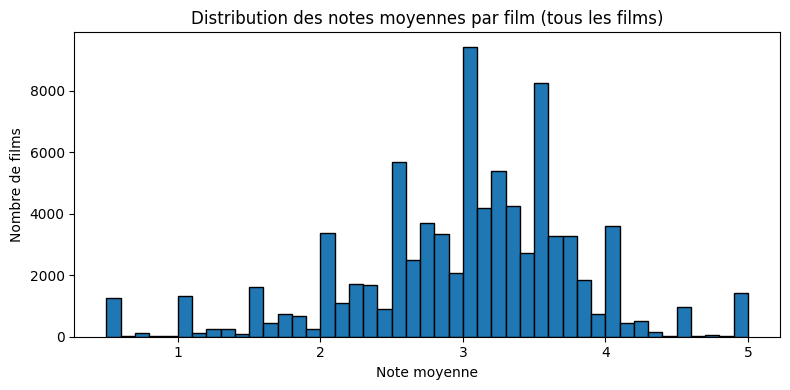

In [22]:
# Note moyenne et nombre de notes pour chaque film
notes_par_film = (
    ratings_movies
    .groupby("movieId")["rating"]
    .agg(note_moyenne="mean", nb_notes="count")
    .reset_index()
)

# 1. Histogramme des notes moyennes, tous les films
fig, ax = plt.subplots(figsize=(8, 4))
notes_par_film["note_moyenne"].plot(kind="hist", bins=45, ax=ax, edgecolor="black")
ax.set_title("Distribution des notes moyennes par film (tous les films)")
ax.set_xlabel("Note moyenne")
ax.set_ylabel("Nombre de films")
plt.tight_layout()
plt.show()


L 'histogramme présente des pics isolés sur les valeurs 0,5, 1, 1,5, … 5 : ce sont les films avec une ou deux notes, dont la moyenne vaut la note reçue. Avec peu de notes, la moyenne est très instable, donc on essaie de filtrer en ne gardant plus que les films qui ont un certain nombre de notes.

Films gardés : 15837


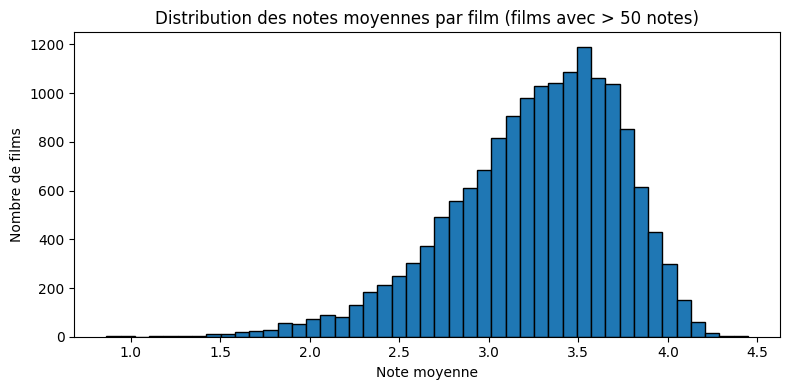

In [23]:
SEUIL = 50  # à modifier

# 2. Histogramme des notes moyennes, films avec plus de SEUIL notes
films_populaires = notes_par_film[notes_par_film["nb_notes"] > SEUIL]
print("Films gardés :", len(films_populaires))

fig, ax = plt.subplots(figsize=(8, 4))
films_populaires["note_moyenne"].plot(kind="hist", bins=45, ax=ax, edgecolor="black")
ax.set_title(f"Distribution des notes moyennes par film (films avec > {SEUIL} notes)")
ax.set_xlabel("Note moyenne")
ax.set_ylabel("Nombre de films")
plt.tight_layout()
plt.show()

Cette représentation se rapproche beaucoup d'une loi normale, de moyenne 3,4 environ, avec une asymétrie à gauche. 
La plupart des films sont bien notés, une moyenne en 3,5 à peu près, qui est supérieure à (5+0,5)/2 = 2,75 qui est le milieu de l'échelle de notes. 

Pourquoi est-ce qu'on note mieux que la moyenne, pourquoi les notes ne suivent pas une loi normale de moyenne 2,75 ?


Les notes plus basses sont rares, notamment parce qu'on ne regarde pas des films aléatoires, mais des films que l'on a envie de regarder (effet de sélection), donc ils ont plus de chances de nous plaire (on peut toutefois être déçu bien sûr, cela n'empêche pas de mettre des mauvaises notes mais rend celles ci moins probables).

### Approche par genres des films

Regardons d'abord comment les genres sont répartis au sein des films

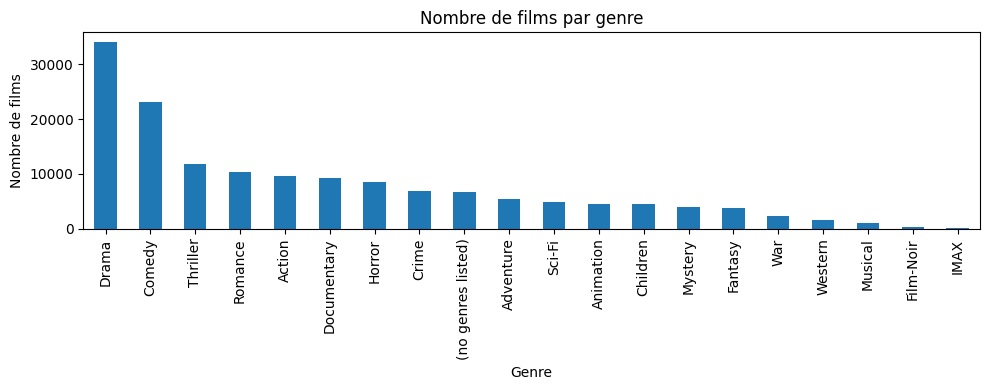

In [24]:
films_par_genre = movies_with_date["genres"].str.split("|").explode().value_counts()

fig, ax = plt.subplots(figsize=(10, 4))
films_par_genre.plot(kind="bar", ax=ax)
ax.set_title("Nombre de films par genre")
ax.set_xlabel("Genre")
ax.set_ylabel("Nombre de films")
plt.tight_layout()
plt.show()


Certains genres sont surreprésentés, même si le classement dans un genre est partiellement arbitraire. Drama et comedy sont surreprésentés car on peut classifier la majorité des films dans une de ces catégories. Certaines films n'ont pas de catégorie (no genres listed), ou ont une catégorie qui a peu de sens (IMAX, qui signifie probablement spectaculaire, même si ce nom représente une technique plutôt qu'un genre cinématographique).

Représentons à présent les notes en fonction des genres.

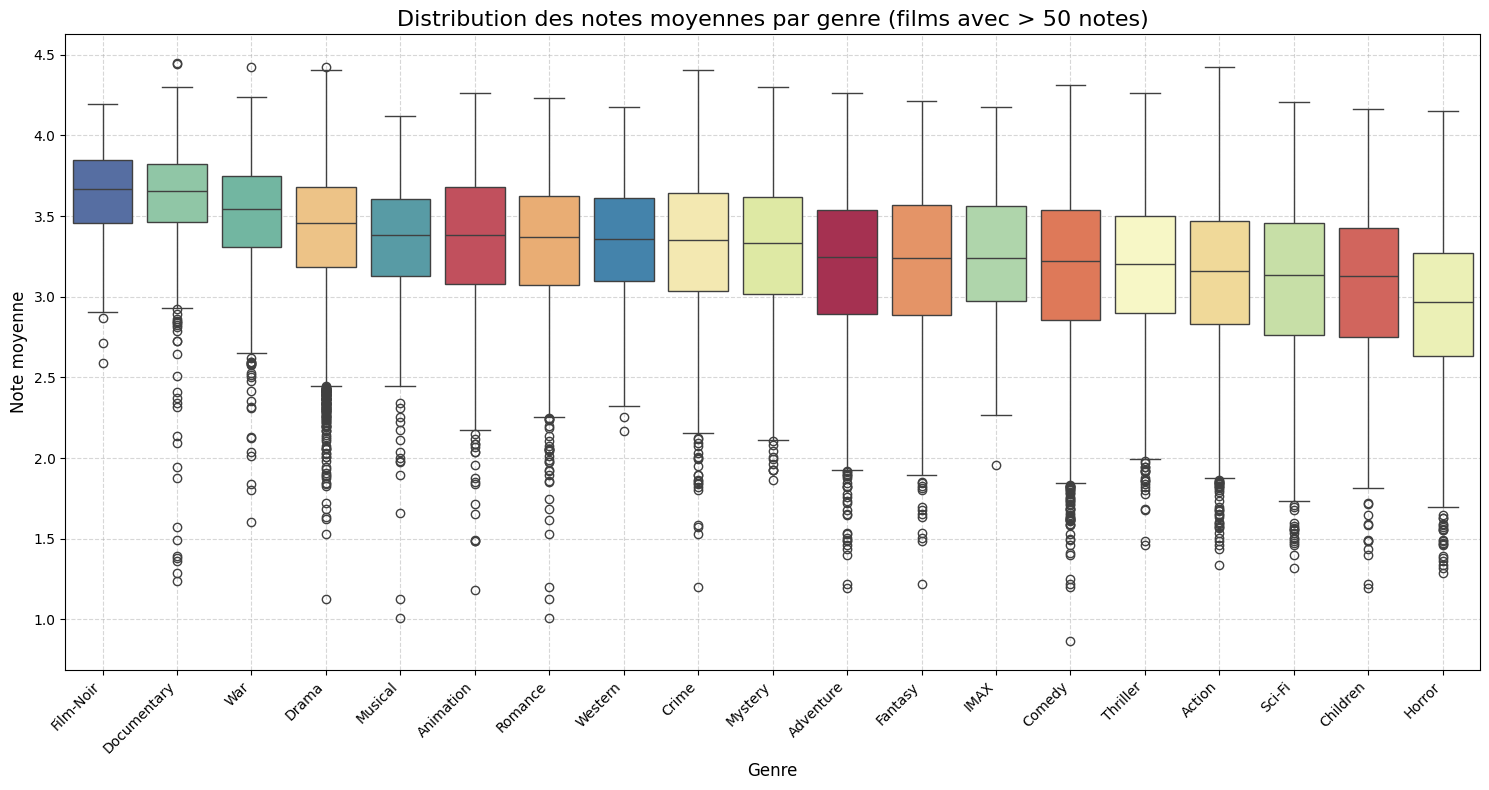

In [25]:
SEUIL = 50  # à faire varier en fonction du nombre de notes chargées

# 1. Note moyenne et nombre de notes par film
notes_par_film = (
    ratings_movies
    .groupby("movieId")["rating"]
    .agg(note_moyenne="mean", nb_notes="count")
    .reset_index()
)

# 2. Garder les films populaires et récupérer leurs genres
films_populaires = notes_par_film[notes_par_film["nb_notes"] > SEUIL]
films_populaires = films_populaires.merge(movies[["movieId", "genres"]], on="movieId")

# 3. Une ligne par genre pour chaque film
films_populaires["genre"] = films_populaires["genres"].str.split("|")
genres_df = films_populaires.explode("genre")
genres_df = genres_df[genres_df["genre"] != "(no genres listed)"]

# 4. Ordre des genres selon la médiane des notes moyennes
ordre = (
    genres_df
    .groupby("genre")["note_moyenne"]
    .median()
    .sort_values(ascending=False)
    .index
)

# 5. Boxplot
plt.figure(figsize=(15, 8))
sns.boxplot(
    data=genres_df,
    x="genre",
    y="note_moyenne",
    order=ordre,
    hue="genre",
    palette="Spectral",
    legend=False,
)
plt.title(f"Distribution des notes moyennes par genre (films avec > {SEUIL} notes)", fontsize=16)
plt.xlabel("Genre", fontsize=12)
plt.ylabel("Note moyenne", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

On enlève certains films qui sont très peu notés qui induisent beaucoup de variance. On peut donc observer les médianes de notes moyennes des films qui appartiennent à chacun des genres. On voit donc qu'il y a une forte différence de notation en fonction du genre. Le genre "film noir" est le mieux noté, avec une note moyenne de 3,7 (probablement peu significative cependant parce qu'on a vu auparavant que le film noir était le deuxième genre le moins représenté), alors que le genre d'horreur est le moins bien noté à 3 en moyenne. 
Toutefois, les différences de médiane entre genres sont du même ordre que la dispersion à l'intérieur d'un genre (boîtes d'environ 0,5 à 0,65), donc le genre n'explique qu'assez partiellement la note d'un film.

### Approche par utilisateurs



In [26]:
print("Nombre d'utilisateurs :", ratings_movies["userId"].nunique())

Nombre d'utilisateurs : 200948


Il y a 200 948 utilisateurs différents. 

In [27]:
# Statistiques par utilisateur
stats_users = (
    ratings_movies
    .groupby("userId")["rating"]
    .agg(note_moyenne="mean", variance="var", nb_notes="count")
    .reset_index()
)
display(stats_users.head())
stats_users.describe()

,userId,note_moyenne,variance,nb_notes
0,1,3.531915,2.365046,141
1,2,4.269231,1.259427,52
2,3,3.588435,1.029797,147
3,4,2.629630,1.088319,27
4,5,3.272727,0.829545,33


,userId,note_moyenne,variance,nb_notes
count,200948.000000,200948.000000,200948.000000,200948.000000
mean,100474.500000,3.704384,0.910827,159.071193
std,58008.835284,0.486605,0.541026,281.501897
min,1.000000,0.500000,0.000000,18.000000
25%,50237.750000,3.415326,0.539147,36.000000
50%,100474.500000,3.725000,0.800000,73.000000
75%,150711.250000,4.025000,1.157143,167.000000
max,200948.000000,5.000000,5.328947,33229.000000


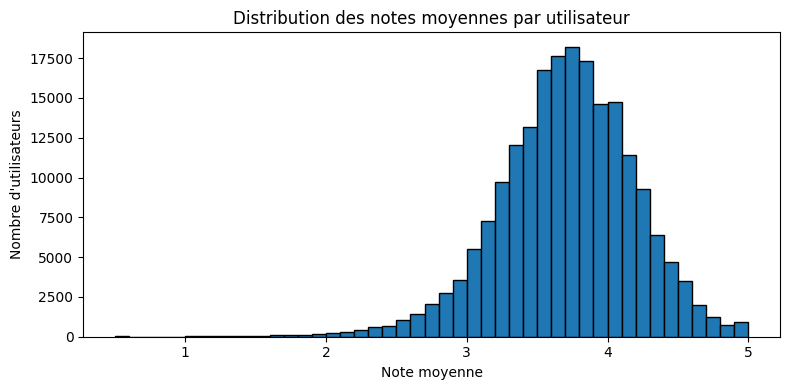

In [28]:
# Histogramme des notes moyennes par utilisateur
fig, ax = plt.subplots(figsize=(8, 4))
stats_users["note_moyenne"].plot(kind="hist", bins=45, ax=ax, edgecolor="black")
ax.set_title("Distribution des notes moyennes par utilisateur")
ax.set_xlabel("Note moyenne")
ax.set_ylabel("Nombre d'utilisateurs")
plt.tight_layout()
plt.show()

In [29]:
stats_users["note_moyenne"].describe()

count    200948.000000
mean          3.704384
std           0.486605
min           0.500000
25%           3.415326
50%           3.725000
75%           4.025000
max           5.000000
Name: note_moyenne, dtype: float64

La répartition des notes moyennes par utilisateur suit environ une loi normale de moyenne 3,7. La plupart des utilisateurs donnent des bonnes notes. 25% des utilisateurs donnent des notes supérieures à 4 en moyenne sont donc généreux.  

La note moyenne (3,54) est inférieure à la moyenne par utilisateur (3,70), donc les utilisateurs qui notent beaucoup notent plus sévèrement.

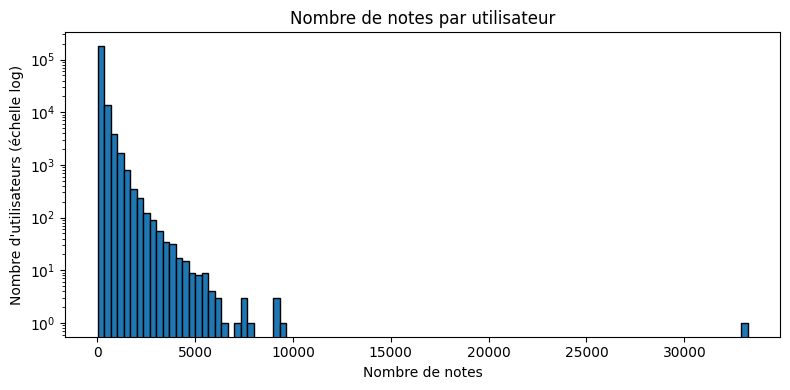

count    200948.000000
mean        159.071193
std         281.501897
min          18.000000
25%          36.000000
50%          73.000000
75%         167.000000
max       33229.000000
Name: nb_notes, dtype: float64

In [30]:
fig, ax = plt.subplots(figsize=(8, 4))
stats_users["nb_notes"].plot(kind="hist", bins=100, ax=ax, edgecolor="black")
ax.set_yscale("log")  # quelques gros utilisateurs écrasent le reste
ax.set_title("Nombre de notes par utilisateur")
ax.set_xlabel("Nombre de notes")
ax.set_ylabel("Nombre d'utilisateurs (échelle log)")
plt.tight_layout()
plt.show()

stats_users["nb_notes"].describe()

Médiane de 73 notes, moyenne de 159, maximum de 33 229 : quelques utilisateurs très actifs allongent fortement la queue de la distribution. L 'échelle logarithmique est nécessaire pour le lire. La moitié des utilisateurs a noté moins de 73 films.

On peut essayer d'observer des profils d'utilisateurs en fonction de leur note moyenne et de leur variance. Le README du dataset indique qu'ils ont tous au moins 20 notes, donc on n'a pas besoin de filtrer les utilisateurs sur ce critère. Le minimum de 18 sur le describe précédent s'explique du fait qu'on a enlevé les films dont on ne connaissait pas la date. 

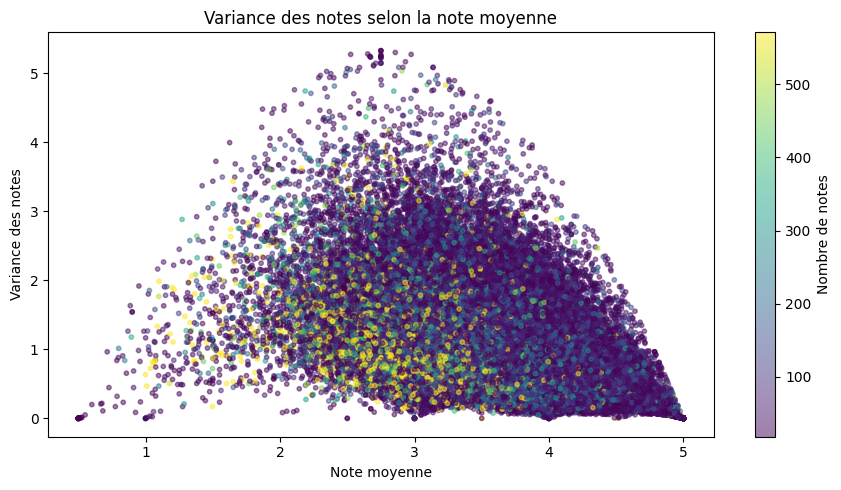

In [31]:
fig, ax = plt.subplots(figsize=(9, 5))
points = ax.scatter(
    stats_users["note_moyenne"],
    stats_users["variance"],
    c=stats_users["nb_notes"],
    cmap="viridis",
    vmax=stats_users["nb_notes"].quantile(0.95),  # évite qu'un seul gros utilisateur écrase les couleurs
    alpha=0.5,
    s=10,
)
fig.colorbar(points, ax=ax, label="Nombre de notes")
ax.set_title("Variance des notes selon la note moyenne")
ax.set_xlabel("Note moyenne")
ax.set_ylabel("Variance des notes")
plt.tight_layout()
plt.show()

Le nuage dessine une arche : la variance est maximale (environ 5) pour une moyenne proche de 3, et tend vers 0 quand la moyenne approche 0,5 ou 5. C'est un effet mécanique de l'échelle bornée, pas un comportement : un utilisateur dont la moyenne est 5 n'a donné que des 5. L'arche n'est cependant pas symétrique, la plupart des utilisateurs se trouvant sur la droite en bas du graphique, autrement dit avec une note moyenne supérieure à 3,5 et une variance inférieure à 2.

Les utilisateurs très actifs (en jaune) semblent plus centraux, et leur proportion est plus élevée dans le quart gauche inférieur du graphique, parmi ceux qui mettent des notes plus faibles, il semble y avoir plus d'utilisateurs habitués. 

Les profils extrêmes (extrémités de l'arche) sont en valeur absolue surtout des utilisateurs peu actifs (points violets), dont les statistiques sont plus bruitées.

# IV - Analyse de l'évolution des notes des films dans le temps

### A) Comment évolue la notation des utilisateurs dans le temps ?

,note_moyenne,nb_notes
anciennete,,
0,3.562411,27173474
1,3.437142,1321663
2,3.418870,855779
3,3.430374,625882
4,3.435341,449878
5,3.410236,332738
6,3.402256,242996
7,3.398283,183500
8,3.401843,137565


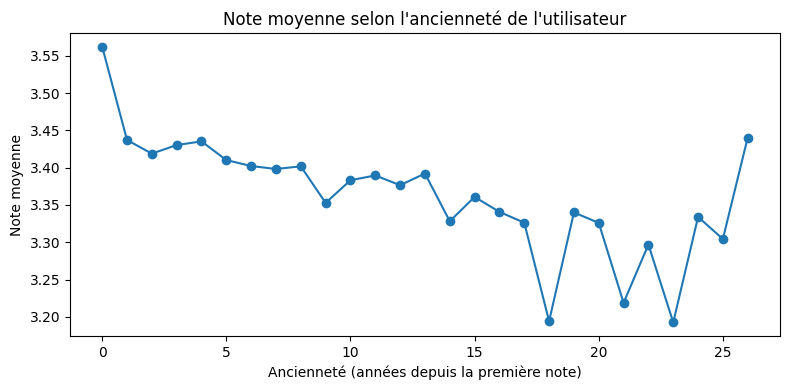

In [32]:
def ajouter_anciennete(df):
    """Ajoute l'ancienneté (en années entières) de chaque note par rapport à la première note de l'utilisateur."""
    df = df.copy()
    premiere_date = df.groupby("userId")["date"].transform("min")
    df["anciennete"] = (df["date"] - premiere_date).dt.days // 365
    return df

notes_anciennete = ajouter_anciennete(ratings_movies)

# Note moyenne et nombre de notes selon l'ancienneté
par_anciennete = notes_anciennete.groupby("anciennete")["rating"].agg(note_moyenne="mean", nb_notes="count")
display(par_anciennete)

fig, ax = plt.subplots(figsize=(8, 4))
par_anciennete["note_moyenne"].plot(marker="o", ax=ax)
ax.set_title("Note moyenne selon l'ancienneté de l'utilisateur")
ax.set_xlabel("Ancienneté (années depuis la première note)")
ax.set_ylabel("Note moyenne")
plt.tight_layout()
plt.show()

On voit que 27 millions de notes sur 32 millions sont situées la première année donc on affine l'analyse sur la première année. A l'autre extrémité, on restreint l'analyse aux notes publiées moins de 15 ans après la première notation de l'utilisateur, car après 15 ans le graphique est moins significatif en raison d'un manque de notes. 

,note_moyenne,nb_notes,nb_utilisateurs
tranche,,,
1re semaine,3.586183,22567063,200948
reste du 1er mois,3.431537,1492667,38715
mois 2 à 6,3.459193,1996338,42063
mois 7 à 12,3.441781,1122490,25649
année 2,3.437049,1319504,22178
année 3,3.418812,854738,14799
année 4,3.429970,625177,10671
année 5,3.435560,449844,8044
année 6,3.410414,332435,6125


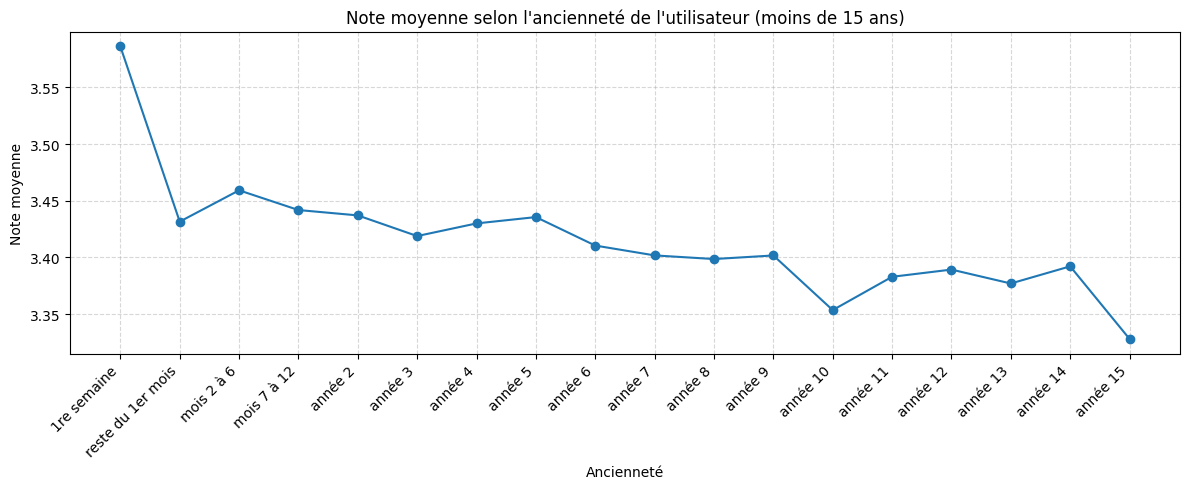

In [33]:
def ajouter_jours(df):
    """Ajoute le nombre de jours écoulés depuis la première note de l'utilisateur."""
    df = df.copy()
    premiere_date = df.groupby("userId")["date"].transform("min")
    df["jours"] = (df["date"] - premiere_date).dt.days
    return df


# Limites des tranches (en jours) et leurs noms
limites = [-1, 7, 30, 182, 365] + [365 * k for k in range(2, 16)]
noms = ["1re semaine", "reste du 1er mois", "mois 2 à 6", "mois 7 à 12"]
noms = noms + [f"année {k}" for k in range(2, 16)]

# Utilisateurs actifs (> 20 notes), ancienneté en jours
notes_jours = ajouter_jours(ratings_movies)

# Tranche de chaque note (les notes après 15 ans sont exclues)
notes_jours["tranche"] = pd.cut(notes_jours["jours"], bins=limites, labels=noms)

par_tranche = (
    notes_jours
    .groupby("tranche", observed=False)["rating"]
    .agg(note_moyenne="mean", nb_notes="count")
)
par_tranche["nb_utilisateurs"] = notes_jours.groupby("tranche", observed=False)["userId"].nunique()
display(par_tranche)

fig, ax = plt.subplots(figsize=(12, 5))
par_tranche["note_moyenne"].plot(marker="o", ax=ax)
ax.set_xticks(range(len(noms)))
ax.set_xticklabels(noms, rotation=45, ha="right")
ax.set_title("Note moyenne selon l'ancienneté de l'utilisateur (moins de 15 ans)")
ax.set_xlabel("Ancienneté")
ax.set_ylabel("Note moyenne")
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

On observe donc que la note moyenne donnée diminue avec l'ancienneté de l'utilisateur. Ils enregistrent toujours la majorité de leurs notes dans la première semaine (22 millions sur 32 millions), et elles sont meilleures que celles enregistrées plus tard. C'est probablement car chaque utilisateur enregistre ses films préférés en premier quand il commence à utiliser la plateforme (effet de comportement), et que les nombreux utilisateurs qui ne donneront pas de notes par la suite (195 506 utilisateurs la première semaine, il n'en reste plus que 38 595 qui enregistrent des notes dans la suite du mois, il y a donc un effet de composition) n'enregistrent probablement que leurs films préférés, et sont peut-être plus bienveillants dans leurs notes que des critiques expérimentés.
Le déclin de la note moyenne, qui se vérifie même si la pente est faible s'explique peut-être par une plus grande exigence envers les films lorsque l'utilisateur en a vu beaucoup, et aussi qu'il prend plus de risques avec les films qu'il regarde, autrement dit il regarde moins de films dont il sait qu'ils vont lui plaire. 

On peut essayer de distinguer l'effet de composition de l'effet de comportement en observant uniquement les utilisateurs qui continuent de noter après la première semaine.

In [34]:
# Note moyenne et nombre de notes de chaque utilisateur, avant et après le 7e jour
semaine1 = notes_jours[notes_jours["jours"] <= 7].groupby("userId")["rating"].agg(["mean", "count"])
apres = notes_jours[notes_jours["jours"] > 7].groupby("userId")["rating"].agg(["mean", "count"])

# On ne garde que les utilisateurs présents dans les deux périodes
memes_users = semaine1.join(apres, lsuffix="_s1", rsuffix="_apres", how="inner")

# Au moins 5 notes dans chaque période
memes_users = memes_users[(memes_users["count_s1"] >= 5) & (memes_users["count_apres"] >= 5)]

# Écart de note moyenne pour chaque utilisateur, puis écart moyen et erreur standard
ecart = memes_users["mean_apres"] - memes_users["mean_s1"]
print("Nombre d'utilisateurs :", len(ecart))
print("Écart moyen :", ecart.mean())
print("Erreur standard :", ecart.std() / len(ecart) ** 0.5)

Nombre d'utilisateurs : 55602
Écart moyen : -0.04290906795686162
Erreur standard : 0.0019381771966831358


Quand on ne garde que les utilisateurs qui ont aussi mis des notes après la première semaine, on voit que la baisse est moins marquée, uniquement -0,04, autrement dit les mêmes utilisateurs notent un peu plus bas après la première semaine, mais cette baisse s'explique surtout parce que ces deux groupes sont composés de populations différentes, ceux qui ne notent pas après la première semaine mettent en effet des meilleures notes. 


On peut aussi tester ces hypothèses en regardant la variance des notes données par les utilisateurs, et son évolution dans le temps.

,variance_moyenne,nb_utilisateurs
tranche,,
1re semaine,0.915062,199723
reste du 1er mois,0.764204,27122
mois 2 à 6,0.770661,33190
mois 7 à 12,0.744376,20585
année 2,0.745947,18736
année 3,0.719321,12701
année 4,0.687858,9013
année 5,0.663510,6854
année 6,0.647322,5217


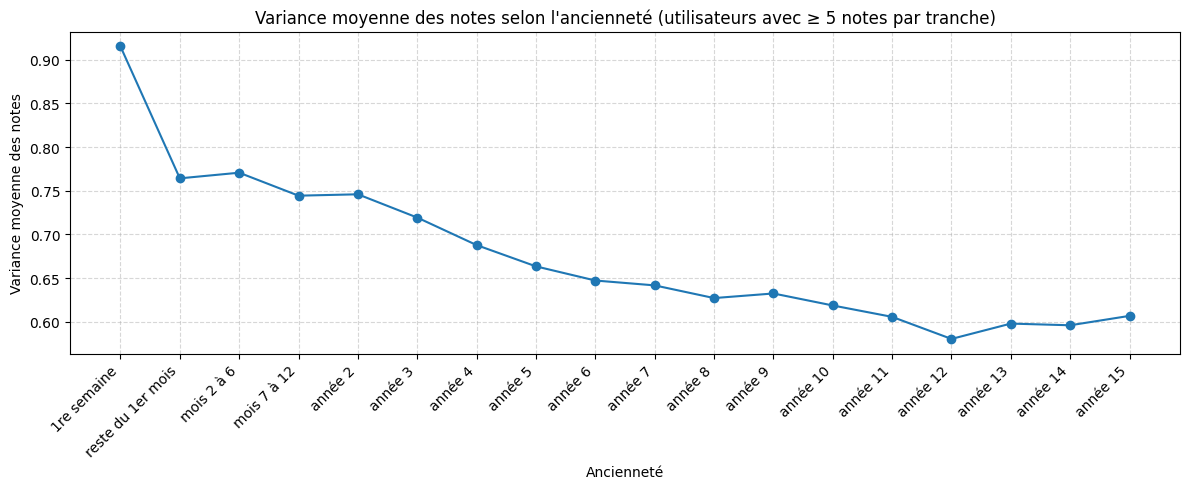

In [35]:
MIN_NOTES = 5  # nombre minimal de notes d'un utilisateur dans une tranche (à modifier)

# Variance des notes de chaque utilisateur dans chaque tranche
var_user_tranche = (
    notes_jours
    .groupby(["userId", "tranche"], observed=True)["rating"]
    .agg(variance="var", nb_notes="count")
    .reset_index()
)
var_user_tranche = var_user_tranche[var_user_tranche["nb_notes"] >= MIN_NOTES]

# Moyenne des variances par tranche
par_tranche_var = var_user_tranche.groupby("tranche", observed=False).agg(
    variance_moyenne=("variance", "mean"),
    nb_utilisateurs=("userId", "nunique"),
)
display(par_tranche_var)

fig, ax = plt.subplots(figsize=(12, 5))
par_tranche_var["variance_moyenne"].plot(marker="o", ax=ax)
ax.set_xticks(range(len(noms)))
ax.set_xticklabels(noms, rotation=45, ha="right")
ax.set_title(f"Variance moyenne des notes selon l'ancienneté (utilisateurs avec ≥ {MIN_NOTES} notes par tranche)")
ax.set_xlabel("Ancienneté")
ax.set_ylabel("Variance moyenne des notes")
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

On est surpris car on observe une baisse de la variance des notes, alors qu'on se serait attendu à ce qu'elle augmente autrement dit que l'utilisateur habitué mette plus de notes extrêmes, par exemple parce qu'il regarde des films plus variés, il prend plus de risques dans ses choix de films. On peut omettre les années supérieures à la dixième année de l'analyse étant donné que moins de 2000 utilisateurs sont concernés, elles sont moins significatives.
Comment expliquer ce paradoxe ?

On peut avancer plusieurs hypothèses. Il y a à nouveau le problème de composition : la première semaine regroupe tout le monde, les tranches suivantes seulement des utilisateurs fidèles, comme pour la note moyenne. 

Cette approche ci semble plutôt signifier que les utilisateurs plus anciens sont en effet plus exigeants, mais qu'ils connaissent mieux leurs goûts, prédisent mieux les films qui vont leur plaire, ce qui explique la baisse de la variance des notes avec l'ancienneté.  

### B) Comment évolue la notation des films dans le temps ?

Après l'analyse de l'évolution des compportements de notation des utilisateurs avec le temps, on regarde cette fois commment évolue la notation globale des films avec le temps.
Ces notations changent-elles avec le temps, observe-t-on les mêmes évolutions pour tous les films ? Existe-t-il des critères/ facteurs permettant de prédire ces évolutions ? 


In [36]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

import importlib
import fonction_analyse_film
importlib.reload(fonction_analyse_film)

from fonction_analyse_film import (
    resumer_notes_par_anciennete, tracer_notes_par_anciennete,
    construire_table_periodes, tracer_trajectoire, tracer_variations, preparer_regression, comparer_modeles)

#### Les notes selon l'ancienneté du film

L'ancienneté est l'année de notation moins l'année de sortie : zéro correspond à la même année civile. On écarte les anciennetés négatives et les dates manquantes.

On compare deux moyennes : l'une où chaque note compte autant, l'autre où chaque film compte autant (cf le code dans fonction_analyse_film pour plus de détails). La première donne davantage de poids aux films les plus notés.
On affiche aussi les effectifs et on masque les moyennes qui s'appuie sur des effectifs inférieurs à 1 000 notes.

Notes utilisées : 31,964,024


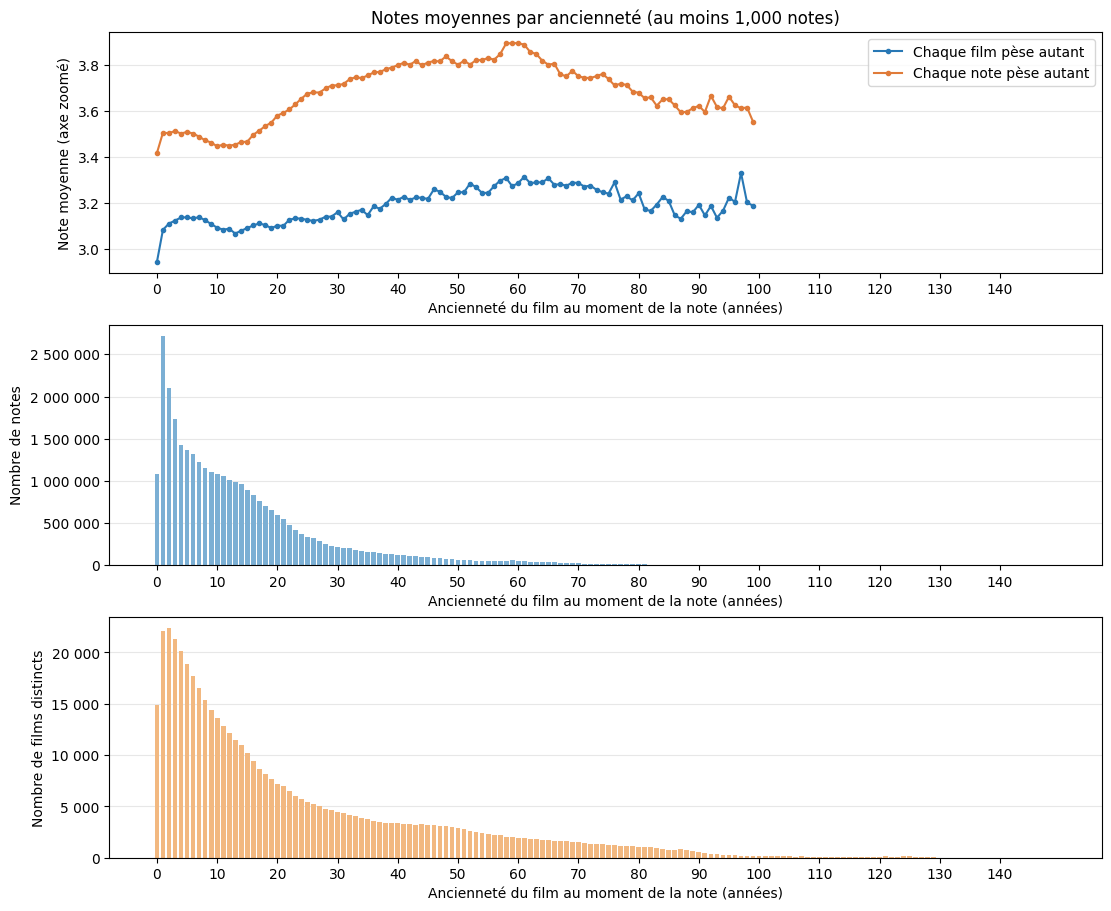

In [37]:
# On agrège une seule fois les notes
par_film = resumer_notes_par_anciennete(ratings_movies)
print(f"Notes utilisées : {par_film['nombre_notes'].sum():,}")
tracer_notes_par_anciennete(par_film, seuil_notes=1000)

Les notes remontent globalement après les premières années, surtout lorsque
chaque note compte autant. Mais les films notés à deux ans ne sont pas les mêmes
que ceux encore notés à soixante ans : par exemple les films sortis en 2015 n'ont pas de données dans les tranches d'ancienneté les plus anciennes. On cherche donc si une remontée apparaît
aussi lorsqu'on fait en sorte de suivre une cohorte plus "fixe".

#### 1. Retrouve-t-on une baisse puis une remontée lorsque l'on s'intéresse à une cohorte "fixe" ?

On compare trois périodes : **0–2 ans, 5–9 ans et 15–19 ans** (c'est un choix). Pour suivre les mêmes films, il faut que ces trois périodes soient couvertes par les données, qui vont de janvier 1995 à octobre 2023. On retient donc les sorties de **1995 à 2003** :

- avant 1995, il manque tout ou partie des notes des premières années ;
- pour un film de 2003, le suivi à 19 ans finit en 2022, une année complète.
  Un film de 2004 atteindrait 19 ans en 2023, qui n'est couverte que jusqu'en octobre.

Cette restriction permet de couvrir les trois périodes pour une même cohorte. On garde les films avec **au moins 10 notes dans chacune** de ces périodes.

On calcule la moyenne de toutes les notes de chaque film sur chaque période, puis la moyenne entre films : chaque film retenu compte autant (méthode de la double moyenne pour éviter les effets de popularité déjà utilisée ci-dessu). Pour retrouver la moyenne d'une période, les moyennes annuelles sont pondérées par leurs
nombres de notes.

Films retenus : 2,059 sur 9,409


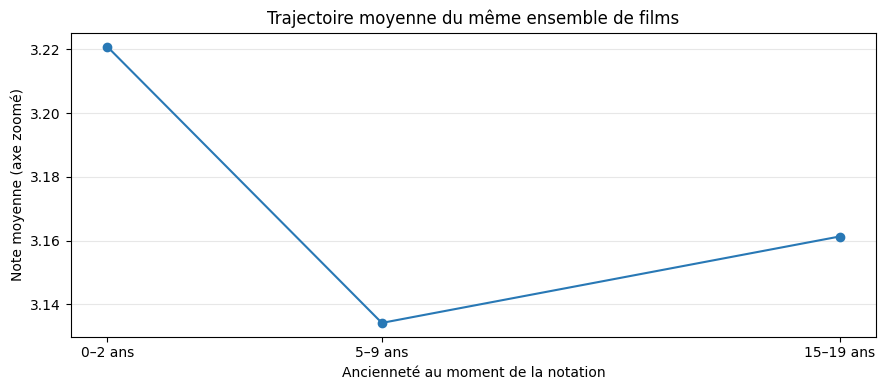

,periode,note_moyenne,nombre_films,nombre_notes
0,0–2 ans,3.221,2059,2589016
1,5–9 ans,3.134,2059,2242820
2,15–19 ans,3.161,2059,1682781


In [38]:
annee_min = 1995
annee_max = 2003
minimum_notes = 10
periodes = [("debut", 0, 2), ("intermediaire", 5, 9), ("tardif", 15, 19)]

table_trajectoires = construire_table_periodes(
    par_film, movies_with_date, periodes, annee_min, annee_max
)
colonnes_effectifs = [f"nb_notes_{nom}" for nom, debut, fin in periodes]
assez_de_notes = (table_trajectoires[colonnes_effectifs] >= minimum_notes).all(axis=1)
comparaison_films = table_trajectoires.loc[assez_de_notes].copy()
print(f"Films retenus : {len(comparaison_films):,} sur {len(table_trajectoires):,}")

resume_trajectoire = tracer_trajectoire(comparaison_films, periodes)
display(resume_trajectoire.round(3))

On conserve **2 059 films sur 9 409**. Leur moyenne passe de **3,221 à 3,134,
puis à 3,161** : une baisse de 0,087 point, suivie d'une reprise de 0,027 point.
La reprise est donc partielle, et la moyenne finale reste sous celle du début.

Cette fois, les films sont les mêmes aux trois points, mais les publics peuvent
changer. Ces moyennes de périodes ne décrivent pas toutes les fluctuations ni
le parcours jusqu'à soixante ans des films de la courbe précédente.

#### 2. La moyenne cache-t-elle des trajectoires différentes ?

On distingue pour chaque film :

- la variation initiale qu'on note B (comme baisse mais bien négative si baisse) : moyenne à 5–9 ans moins moyenne à 0–2 ans ;
- la reprise R : moyenne à 15–19 ans moins moyenne à 5–9 ans.

Une baisse puis une remontée correspond à B négatif et R positif. On compare
les effectifs et les amplitudes pour voir si la trajectoire moyenne est répandue.

,nombre_films,variation_initiale_mediane,reprise_mediane,part_films_pct
profil,,,,
Baisse puis remontée,797,-0.206,0.164,38.708
Baisse sur les deux phases,559,-0.146,-0.121,27.149
Hausse puis baisse,381,0.136,-0.143,18.504
Hausse sur les deux phases,319,0.117,0.111,15.493
Variation nulle sur une phase,3,0.096,0.000,0.146


Reprise positive : 54.2% ; reprise médiane : +0.023 point


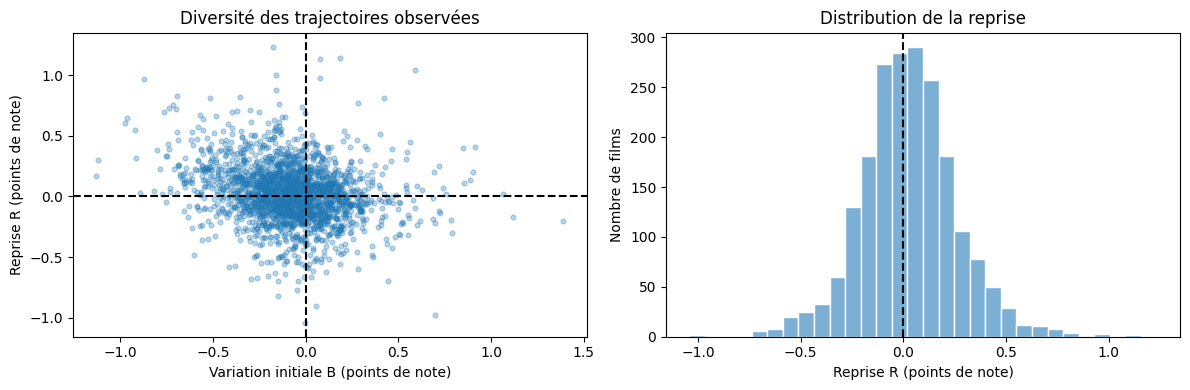

In [39]:
comparaison_films["variation_initiale"] = (
    comparaison_films["note_intermediaire"] - comparaison_films["note_debut"]
)
comparaison_films["reprise"] = (
    comparaison_films["note_tardif"] - comparaison_films["note_intermediaire"]
)
B = comparaison_films["variation_initiale"]
R = comparaison_films["reprise"]

# Ces profils décrivent les signes observés, sans seuil de significativité.
comparaison_films["profil"] = "Variation nulle sur une phase"
comparaison_films.loc[(B < 0) & (R > 0), "profil"] = "Baisse puis remontée"
comparaison_films.loc[(B < 0) & (R < 0), "profil"] = "Baisse sur les deux phases"
comparaison_films.loc[(B > 0) & (R > 0), "profil"] = "Hausse sur les deux phases"
comparaison_films.loc[(B > 0) & (R < 0), "profil"] = "Hausse puis baisse"

resume_profils = comparaison_films.groupby("profil").agg(
    nombre_films=("movieId", "count"),
    variation_initiale_mediane=("variation_initiale", "median"),
    reprise_mediane=("reprise", "median")
).sort_values("nombre_films", ascending=False)
resume_profils["part_films_pct"] = 100 * resume_profils["nombre_films"] / len(comparaison_films)
display(resume_profils.round(3))
print(f"Reprise positive : {(R > 0).mean():.1%} ; reprise médiane : {R.median():+.3f} point")
tracer_variations(comparaison_films)

**797 films, soit 38,7 %, baissent puis remontent** : cette trajectoire ne concerne
donc pas tous les films. Au total, **54,2 %** ont une reprise positive, mais la
reprise médiane reste faible : **+0,023 point**. Veut-elle tout de même dire quelque chose; c'est ce que cherche la partie suivante.


#### Quelle est l'ampleur des variations tardives aussi appelé reprise ?

La hausse moyenne est faible. On regarde donc la dispersion et les amplitudes
avant de chercher à les expliquer pour voir si cet effet de reprise existe réellement (au sens: est significatif). On se dit notamment que s'il existe une certaine quantité de films dont la reprisee est supérieure en valeur absolue à 0,25 (choix), cet effet "reprise" existe bien.

In [40]:
# Une faible moyenne peut cacher des hausses et des baisses qui se compensent.
resume_variations = R.agg(["mean", "median", "std", "var", "min", "max"])
resume_variations.index = [
    "Moyenne (points)", "Médiane (points)", "Écart-type (points)",
    "Variance (points²)", "Minimum (points)", "Maximum (points)"
]
display(resume_variations.round(3))
print(
    f"Au moins 0,25 point : {(R >= 0.25).sum()} hausses ({(R >= 0.25).mean():.1%}) ; "
    f"{(R <= -0.25).sum()} baisses ({(R <= -0.25).mean():.1%})"
)

# Deux exemples parmi les films ayant au moins 100 notes dans chaque période.
films_documentes = comparaison_films.loc[
    (comparaison_films[colonnes_effectifs] >= 100).all(axis=1)
].sort_values("reprise")
display(films_documentes.iloc[[0, -1]][[
    "title", "note_intermediaire", "note_tardif", "reprise",
    "nb_notes_intermediaire", "nb_notes_tardif"
]].round(3))

Moyenne (points)       0.027
Médiane (points)       0.023
Écart-type (points)    0.243
Variance (points²)     0.059
Minimum (points)      -1.042
Maximum (points)       1.234
Name: reprise, dtype: float64

Au moins 0,25 point : 301 hausses (14.6%) ; 200 baisses (9.7%)


,title,note_intermediaire,note_tardif,reprise,nb_notes_intermediaire,nb_notes_tardif
345,Wallace & Gromit: The Best of Aardman Animation,4.195,3.526,-0.670,2309.0,978.0
1469,Pokémon: The First Movie,1.760,2.994,1.234,418.0,309.0


La moyenne est de **+0,027 point**, mais l'écart-type atteint **0,243 point**
(variance : **0,059 point²**). **301 films (14,6 %) gagnent au moins 0,25 point**
et **200 (9,7 %) perdent au moins autant**. Parmi les films suffisamment notés,
Pokémon: The First Movie gagne **1,234 point**, tandis que Wallace & Gromit:
The Best of Aardman Animation perd **0,670 point**.

On observe donc des hausses et des baisses marquées pour certains films tardivement (c'est à dire entre la note moyenne intermédiaire et la note moyenne tardive),
ce qui motive l'étude de leurs différences.
C'est cet effet tardif qui nous a le plus intéressé: il n'est pas forcément des plus intuitifs mais existe bien. Il pourrait rendre compte d'un effet de bonification tardif avec l'âge qui pourrait ressembler à un effet "le film devient un classique" ou un effet inverse dans le cas d'une reprise négative: un effet de "mauvais vieillissement". Est ce le cas ? La suite tente d'y répondre.

#### 3. Quels facteurs sont associés à la reprise ?

La remontée (reprise positive) nous a intéressés car elle évoque l'idée de films réévalués avec le temps, voire devenus des classiques. [Allen et Lincoln (2004)](https://doi.org/10.1353/sof.2004.0030) étudient cette consécration rétrospective par les institutions cinématographiques. [Bollen, Graus et Willemsen (2012)](https://doi.org/10.1145/2365952.2365998) observent une hausse des notes avec l'ancienneté sur MovieLens, mais ne la retrouvent pas en mesurant le délai depuis le visionnage. Cette piste reste exploratoire : une hausse de note ne suffit pas à identifier un classique, qui peut aussi conserver une note élevée.

On cherche donc quelles caractéristiques sont associées aux différences d'évolution entre films à l'aide d'une régression sur la reprise. La régression porte sur les mêmes **2 059 films**. La variable `reprise` est la variation entre 5–9 et 15–19 ans : **positive pour une hausse, négative pour une baisse**.
Voici les modèles de régression allant du moins au plus fin que l'on a testé avec leur variable explicatives associés:

- **M1** : Popularité initiale (c'est le nombre de notes à 0–2 ans de la sortie, transformé en
`log(1 + nombre de notes)` pour la régression), genres et année de sortie (elle est intégrée sous forme d’indicatrices C(year) : par exemple C(2000) vaut 1 si le film est sorti en 2000, 0 sinon et l'indicatrice de 1995 est constamment nul car 1995 est année de référence). Ce sont les premières idées de variables explicatives de la reprise qui nous sont venues.

- **M2** : M1 + moyenne initiale (des notes du film sur la période 0-2 ans). Cela permet d'étudier la reprise à réception initiale comparable.

- **M3** : M2 + évolution de l'attention (L'attention est mesurée par le logarithme du rapport entre les nombres de notes à 15–19 ans et à 5–9 ans. Ces deux périodes durent cinq ans : une valeur plus élevée indique un volume qui augmente davantage ou baisse moins.) Cela permet d'étudier le lien entre reprise et maintien de l'attention autour du film.

On garde les genres présents dans au moins 30 films. Les intervalles à 95 % utilisent des erreurs standards robustes HC3 pour autoriser une éventuelle hétéroscédasticité

In [41]:
from fonction_analyse_film import (
    preparer_regression, comparer_modeles)


# On réutilise les moyennes et effectifs déjà calculés, sans revenir aux 32 M de notes.
df_reg, genres_retenus = preparer_regression(comparaison_films, minimum_films_genre=30)

formule_base = "reprise ~ log_nb_notes_debut + C(year)"
if len(genres_retenus) > 0:
    formule_base += " + " + " + ".join(genres_retenus)
formule_initiale = formule_base + " + note_debut"
formule_finale = formule_initiale + " + evolution_attention"

modele_base = smf.ols(formule_base, data=df_reg).fit(cov_type="HC3")
modele_initial = smf.ols(formule_initiale, data=df_reg).fit(cov_type="HC3")
modele_final = smf.ols(formule_finale, data=df_reg).fit(cov_type="HC3")

modeles = [("M1 : base", modele_base), ("M2 : réception initiale", modele_initial),
           ("M3 : attention", modele_final)]
comparaison_modeles = comparer_modeles(modeles)
display(comparaison_modeles.round(4))

,modele,nombre_films,R2,R2_ajuste,RMSE
0,M1 : base,2059,0.0985,0.0874,0.2302
1,M2 : réception initiale,2059,0.1695,0.1589,0.2210
2,M3 : attention,2059,0.1906,0.1798,0.2181


L'ajout de la moyenne initiale fait passer le **R² de 0,098 à 0,169** ;
l'attention le porte ensuite à **0,191**. Le premier ajout améliore donc
davantage l'ajustement. Le R² ajusté progresse aussi, et le RMSE (racine de
la moyenne des résidus au carré) baisse de **0,230 à 0,218 point**.
M3 résume ainsi **19,1 % de la variabilité de la reprise** sur les mêmes
2 059 films.

##### M1 : Les premières associations

In [42]:
display(modele_base.summary())

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                reprise   R-squared:                       0.098
Model:                            OLS   Adj. R-squared:                  0.087
Method:                 Least Squares   F-statistic:                     8.941
Date:                Tue, 24 Nov 2026   Prob (F-statistic):           8.42e-32
Time:                        20:24:51   Log-Likelihood:                 102.52
No. Observations:                2059   AIC:                            -153.0
Df Residuals:                    2033   BIC:                            -6.661
Df Model:                          25                                         
Covariance Type:                  HC3                                         
======================================================================================
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept              0.1276      0.039      3.246      0.001       0.051       0.205
C(year)[T.1996]        0.0056      0.026      0.219      0.827      -0.045       0.056
C(year)[T.1997]        0.0016      0.026      0.062      0.951      -0.049       0.052
C(year)[T.1998]        0.0014      0.026      0.054      0.957      -0.050       0.053
C(year)[T.1999]        0.0178      0.024      0.756      0.450      -0.028       0.064
C(year)[T.2000]       -0.0653      0.025     -2.662      0.008      -0.113      -0.017
C(year)[T.2001]       -0.0470      0.024     -1.929      0.054      -0.095       0.001
C(year)[T.2002]       -0.0442      0.024     -1.857      0.063      -0.091       0.002
C(year)[T.2003]       -0.0721      0.025     -2.923      0.003      -0.120      -0.024
log_nb_notes_debut    -0.0091      0.004     -2.026      0.043      -0.018      -0.000
genre_Action           0.0450      0.015      2.926      0.003       0.015       0.075
genre_Adventure        0.0068      0.022      0.317      0.751      -0.035       0.049
genre_Animation        0.0092      0.042      0.218      0.827      -0.074       0.092
genre_Children         0.1351      0.029      4.632      0.000       0.078       0.192
genre_Comedy          -0.0508      0.014     -3.721      0.000      -0.078      -0.024
genre_Crime            0.0226      0.015      1.518      0.129      -0.007       0.052
genre_Documentary     -0.0875      0.040     -2.199      0.028      -0.165      -0.010
genre_Drama           -0.0554      0.013     -4.415      0.000      -0.080      -0.031
genre_Fantasy         -0.0335      0.025     -1.344      0.179      -0.082       0.015
genre_Horror           0.0616      0.021      2.923      0.003       0.020       0.103
genre_Musical          0.1006      0.039      2.582      0.010       0.024       0.177
genre_Mystery         -0.0086      0.019     -0.441      0.659      -0.047       0.030
genre_Romance         -0.0147      0.013     -1.105      0.269      -0.041       0.011
genre_Sci_Fi           0.0388      0.020      1.940      0.052      -0.000       0.078
genre_Thriller         0.0229      0.014      1.686      0.092      -0.004       0.049
genre_War             -0.0021      0.022     -0.095      0.925      -0.046       0.042
==============================================================================
Omnibus:                       83.884   Durbin-Watson:                   2.010
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              245.846
Skew:                           0.094   Prob(JB):                     4.12e-54
Kurtosis:                       4.682   Cond. No.                         74.5
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity robust (HC3)
"""

M1 explique 9,8 % de la variabilité de la reprise. À autres caractéristiques comparables, Children (+0,135 point), Musical (+0,101), Horror (+0,062) et Action (+0,045) sont associés à une reprise plus forte. Comedy (−0,051), Drama (−0,055) et Documentary (−0,088) sont associés à une reprise plus faible. Ces associations sont significatives au seuil de 5 % ; celles des autres genres ne le sont pas.

La popularité initiale, exprimée en logarithme, présente une association négative de faible ampleur (−0,009 ; p = 0,043), tout juste significative à 5 %. Parmi les années de sortie, seules 2000 et 2003 présentent une reprise significativement inférieure à celle de 1995, respectivement de 0,065 et 0,072 point.

Ces résultats restent exploratoires : les tests sont individuels, sans correction pour les comparaisons multiples, et une absence de significativité ne prouve pas une absence d’association.


##### M2 : Tenir compte de la réception initiale

In [43]:
display(modele_initial.summary())

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                reprise   R-squared:                       0.169
Model:                            OLS   Adj. R-squared:                  0.159
Method:                 Least Squares   F-statistic:                     13.40
Date:                Tue, 24 Nov 2026   Prob (F-statistic):           4.38e-53
Time:                        20:24:51   Log-Likelihood:                 187.01
No. Observations:                2059   AIC:                            -320.0
Df Residuals:                    2032   BIC:                            -168.0
Df Model:                          26                                         
Covariance Type:                  HC3                                         
======================================================================================
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept              0.4956      0.050     10.010      0.000       0.399       0.593
C(year)[T.1996]        0.0125      0.025      0.500      0.617      -0.036       0.061
C(year)[T.1997]       -0.0053      0.025     -0.214      0.831      -0.054       0.043
C(year)[T.1998]       -0.0189      0.025     -0.761      0.446      -0.068       0.030
C(year)[T.1999]       -0.0059      0.022     -0.265      0.791      -0.050       0.038
C(year)[T.2000]       -0.0808      0.024     -3.424      0.001      -0.127      -0.035
C(year)[T.2001]       -0.0577      0.024     -2.455      0.014      -0.104      -0.012
C(year)[T.2002]       -0.0548      0.023     -2.379      0.017      -0.100      -0.010
C(year)[T.2003]       -0.0808      0.024     -3.377      0.001      -0.128      -0.034
log_nb_notes_debut     0.0102      0.005      2.133      0.033       0.001       0.020
genre_Action           0.0153      0.015      1.029      0.304      -0.014       0.044
genre_Adventure        0.0153      0.020      0.756      0.450      -0.024       0.055
genre_Animation        0.0437      0.039      1.130      0.259      -0.032       0.120
genre_Children         0.0840      0.028      2.990      0.003       0.029       0.139
genre_Comedy          -0.0601      0.013     -4.527      0.000      -0.086      -0.034
genre_Crime            0.0295      0.014      2.059      0.039       0.001       0.058
genre_Documentary      0.0266      0.041      0.653      0.514      -0.053       0.106
genre_Drama           -0.0005      0.013     -0.040      0.968      -0.026       0.025
genre_Fantasy         -0.0290      0.024     -1.233      0.218      -0.075       0.017
genre_Horror           0.0191      0.021      0.925      0.355      -0.021       0.059
genre_Musical          0.0900      0.038      2.391      0.017       0.016       0.164
genre_Mystery          0.0072      0.019      0.381      0.703      -0.030       0.044
genre_Romance         -0.0121      0.013     -0.950      0.342      -0.037       0.013
genre_Sci_Fi           0.0301      0.019      1.617      0.106      -0.006       0.067
genre_Thriller         0.0144      0.013      1.109      0.268      -0.011       0.040
genre_War              0.0175      0.022      0.802      0.423      -0.025       0.060
note_debut            -0.1539      0.014    -11.259      0.000      -0.181      -0.127
==============================================================================
Omnibus:                       75.853   Durbin-Watson:                   2.029
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              218.175
Skew:                          -0.003   Prob(JB):                     4.21e-48
Kurtosis:                       4.595   Cond. No.                         87.1
==============================================================================

Dans M2,l’ajout de la moyenne initiale porte le **R² de 9,8 % à 16,9 %**. À autres caractéristiques comparables, **un point de note initiale supplémentaire est associé à 0,154 point de reprise en moins**. Cette association est **nettement significative** (p < 0,001 ; intervalle à 95 % : [−0,181 ; −0,127]), sans démontrer un mécanisme causal.

À réception initiale comparable, **Children (+0,084), Musical (+0,090) et Crime (+0,029)** sont associés à une reprise **plus forte** (que celle des films sans ce genre), et **Comedy (−0,060) à une reprise plus faible** (que celle des films sans ce genre). Ces coefficients sont significatifs au seuil individuel de 5 %. Action, Documentary, Drama et Horror, significatifs dans M1, ne le sont plus dans M2 : leurs premières associations sont donc sensibles à la prise en compte de la réception initiale.

La popularité initiale passe de −0,009 dans M1 (p = 0,043) à +0,010 dans M2 (p = 0,033) : son association reste faible et dépend du modèle. Les coefficients d’année mesurent les écarts par rapport aux films de 1995, référence commune aux trois modèles. Dans M2, les films de 2000–2003 présentent chacun une variation tardive plus faible, à autres caractéristiques comparables ; ces quatre écarts sont significatifs à 5 %.

##### M3 : Ajouter l'évolution de l'attention

In [44]:
display(modele_final.summary())
print(
    "Écart associé à un doublement du rapport des volumes : "
    f"{modele_final.params['evolution_attention'] * np.log(2):+.3f} point de reprise"
)

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                reprise   R-squared:                       0.191
Model:                            OLS   Adj. R-squared:                  0.180
Method:                 Least Squares   F-statistic:                     15.30
Date:                Tue, 24 Nov 2026   Prob (F-statistic):           1.33e-63
Time:                        20:24:51   Log-Likelihood:                 213.50
No. Observations:                2059   AIC:                            -371.0
Df Residuals:                    2031   BIC:                            -213.4
Df Model:                          27                                         
Covariance Type:                  HC3                                         
=======================================================================================
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept               0.6696      0.054     12.467      0.000       0.564       0.775
C(year)[T.1996]        -0.0021      0.025     -0.085      0.932      -0.051       0.047
C(year)[T.1997]        -0.0442      0.025     -1.746      0.081      -0.094       0.005
C(year)[T.1998]        -0.0757      0.026     -2.907      0.004      -0.127      -0.025
C(year)[T.1999]        -0.0646      0.024     -2.722      0.006      -0.111      -0.018
C(year)[T.2000]        -0.1690      0.027     -6.245      0.000      -0.222      -0.116
C(year)[T.2001]        -0.1655      0.028     -5.845      0.000      -0.221      -0.110
C(year)[T.2002]        -0.1632      0.028     -5.830      0.000      -0.218      -0.108
C(year)[T.2003]        -0.1903      0.029     -6.571      0.000      -0.247      -0.134
log_nb_notes_debut      0.0022      0.005      0.442      0.658      -0.007       0.012
genre_Action            0.0135      0.015      0.922      0.357      -0.015       0.042
genre_Adventure         0.0082      0.020      0.402      0.687      -0.032       0.048
genre_Animation         0.0298      0.039      0.761      0.447      -0.047       0.106
genre_Children          0.0606      0.028      2.142      0.032       0.005       0.116
genre_Comedy           -0.0594      0.013     -4.562      0.000      -0.085      -0.034
genre_Crime             0.0254      0.014      1.825      0.068      -0.002       0.053
genre_Documentary       0.0521      0.041      1.265      0.206      -0.029       0.133
genre_Drama             0.0040      0.013      0.309      0.757      -0.021       0.029
genre_Fantasy          -0.0378      0.024     -1.599      0.110      -0.084       0.009
genre_Horror            0.0116      0.021      0.564      0.573      -0.029       0.052
genre_Musical           0.0904      0.037      2.431      0.015       0.018       0.163
genre_Mystery           0.0034      0.018      0.182      0.856      -0.033       0.040
genre_Romance          -0.0097      0.012     -0.781      0.435      -0.034       0.015
genre_Sci_Fi            0.0252      0.018      1.376      0.169      -0.011       0.061
genre_Thriller          0.0102      0.013      0.806      0.420      -0.015       0.035
genre_War               0.0112      0.020      0.551      0.582      -0.029       0.051
note_debut             -0.1540      0.014    -11.172      0.000      -0.181      -0.127
evolution_attention     0.0650      0.009      7.007      0.000       0.047       0.083
==============================================================================
Omnibus:                       83.008   Durbin-Watson:                   2.029
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              249.472
Skew:                           0.055   Prob(JB):                     6.73e-55
Kurtosis:                       4.702  

Écart associé à un doublement du rapport des volumes : +0.045 point de reprise


L’ajout de l’évolution de l’attention porte le R² de 16,9 % à 19,1 %. À autres caractéristiques comparables, doubler le rapport entre le nombre de notes à 15–19 ans et celui à 5–9 ans est associé à +0,045 point de variation tardive. Cette association est significative (p < 0,001).

Un point de moyenne initiale supplémentaire est associé à 0,154 point de variation tardive en moins (p < 0,001), résultat stable par rapport à M2. En revanche, l’association avec la popularité initiale n’est plus significative (p = 0,658).

La présence des genres Children (+0,061) et Musical (+0,090) est associée à une variation plus élevée, celle de Comedy (−0,059) à une variation plus faible, comparativement à leur absence. Ces écarts sont significatifs à 5 % ; les autres genres, dont Crime, ne le sont pas.

Les années de sortie 1998–2003 présentent chacune un écart négatif significatif à 5 % par rapport à 1995.

L’attention étant mesurée pendant les mêmes périodes que la variation des notes, on ne peut pas établir le sens de la causalité.


##### Tracé des résidus de M3 en fonction des variations estimées par M3

Ces axes permettent de voir si les erreurs diffèrent selon que le modèle estime une baisse ou une hausse. Une courbure du nuage pourrait révéler une tendance mal décrite par exemple.

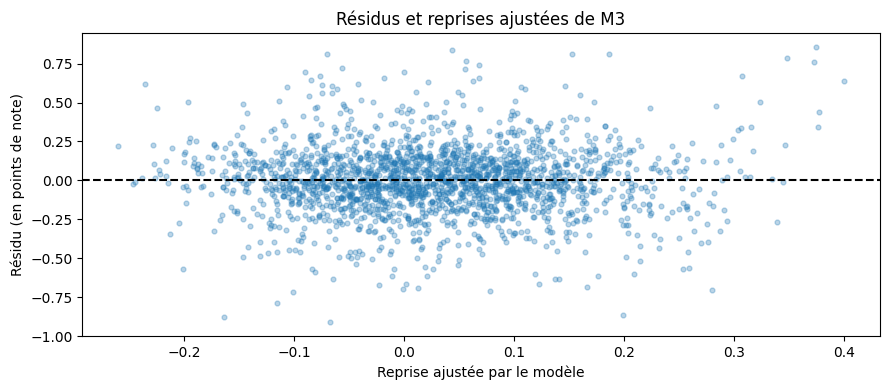

In [46]:
# On regarde aussi ce que le modèle ne parvient pas à résumer.
fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(modele_final.fittedvalues, modele_final.resid, s=12, alpha=0.3)
ax.axhline(0, color="black", linestyle="--")
ax.set_title("Résidus et reprises ajustées de M3")
ax.set_xlabel("Reprise ajustée par le modèle")
ax.set_ylabel("Résidu (en points de note)")
plt.tight_layout()
plt.show()

M3 rend compte de 19,1 % de la variabilité observée et fait ressortir certaines différences moyennes entre films. L’ajustement reste toutefois limité pour les trajectoires individuelles : même lorsque la variation estimée est proche de zéro, certains résidus dépassent ±0,5 point. Les variables retenues apportent donc une information sur les tendances moyennes, mais les évolutions les plus marquées restent difficiles à reconstituer.

#### Bilan des trois régressions

Sur les mêmes **2 059 films**, on étudie la variation des notes entre **5–9 et 15–19 ans**, positive ou négative. Le R² passe de **9,8 % dans M1** à **16,9 % dans M2**, puis **19,1 % dans M3**. L’ajout de la moyenne initiale apporte donc le principal gain d’ajustement ; l’attention complète plus modestement l’analyse.

**Résultats à retenir, à autres caractéristiques comparables**

- **Moyenne initiale :** un point supplémentaire à 0–2 ans est associé à **0,154 point de variation tardive en moins**. Cette association est stable entre M2 et M3 et significative (**p < 0,001**), sans impliquer nécessairement une baisse des notes.

- **Évolution de l’attention :** dans M3, doubler le rapport entre les volumes de notes tardif et intermédiaire est associé à **+0,045 point de variation tardive** (**p < 0,001**). L’association est significative, mais d’ampleur modeste.

- **Genres :** Comedy est associé à une variation plus faible ; Children et Musical à une variation plus forte, comparativement à l’absence du genre concerné. Ces associations gardent leur signe et restent significatives à 5 % dans les trois modèles. Dans M3, les coefficients valent respectivement **−0,059, +0,061 et +0,090** ; les autres genres ne sont pas significatifs.

- **Popularité initiale :** son coefficient change de signe entre M1 et M2, puis n’est plus significatif dans M3 (**p = 0,658**). L’association dépend donc des variables incluses.

- **Année de sortie :** dans M3, les cohortes **1998–2003** présentent chacune une variation significativement inférieure à celle de **1995**, référence commune aux trois modèles, au seuil de 5 %.

**Portée et limites**

- **Une sélection de films durablement notés.** On conserve 2 059 films sur 9 409, avec au moins dix notes dans chaque fenêtre. Les résultats concernent donc les films qui conservent un public jusqu’à 15–19 ans, sans renseigner ceux qui cessent d’être notés.

- **Vieillissement et calendrier restent mêlés.** Pour un même film, passer de 5–9 à 15–19 ans déplace aussi la fenêtre de notation de dix ans. Les utilisateurs et les pratiques peuvent changer. Comparer les mêmes films élimine le changement de composition en films, mais ne permet pas d’attribuer leur évolution au seul vieillissement. `C(year)` distingue les cohortes de sortie sans résoudre ce problème.

- **L’attention accompagne la variation, sans nécessairement la provoquer.** Une meilleure appréciation peut attirer davantage de notes ; l’arrivée d’un nouveau public peut aussi modifier simultanément leur nombre et leur moyenne. Le coefficient de M3 mesure cette coévolution, sans départager ces mécanismes.

- **Les significativités restent conditionnelles.** HC3 autorise des variances d’erreur différentes, mais ne corrige pas la dépendance créée par les utilisateurs communs. Les tests sur les nombreux genres ne sont pas corrigés pour les comparaisons multiples : les associations de Children (p = 0,032) et Musical (p = 0,015) sont notamment moins nettes que celle de Comedy (p < 0,001).

#### Conclusion sur les régressions

La courbe générale suggérait une remontée des notes après la baisse fréquente des premières années. En suivant les mêmes films, on retrouve, sur la cohorte retenue, une reprise faible et partielle en moyenne, derrière laquelle se cachent des hausses et des baisses importantes.

Les régressions permettent de préciser ces différences : à autres caractéristiques comparables, l’évolution tardive est plus favorable aux films initialement moins bien reçus et dont le volume de notes se maintient mieux. La popularité initiale ne présente, elle, aucune association stable entre modèles.

**Notre analyse conduit donc à dépasser l’idée d’une trajectoire commune : les premières évaluations ne figent pas la réception d’un film, et le maintien de l’attention accompagne des évolutions plus favorables. Ces facteurs éclairent une partie de la diversité observée, sans suffire à reconstituer chaque trajectoire.**



## Conclusion globale

Notre problématique était de comprendre **ce qu’une note MovieLens révèle du film et de l’utilisateur, et comment elle évolue avec l’ancienneté de chacun**. Les notes sont globalement favorables (**3,54/5**) et diffèrent selon les genres ; Les utilisateurs très actifs notent en moyenne plus bas, mais la comparaison des mêmes personnes entre leurs débuts et la suite de leur activité ne révèle qu’une faible baisse moyenne des notes. Dans la cohorte de films suivis (IV.B), la reprise moyenne est faible et partielle ; les régressions associent une évolution tardive plus favorable à une réception initiale moins bonne et à un meilleur maintien du volume de notes. **Les notes moyennes doivent donc être interprétées avec le public qui les produit et le contexte de notation, sans considérer les associations avec l’âge, l’expérience ou la popularité comme des effets causaux.** Pour approfondir, on pourrait recueillir les dates de visionnage afin de distinguer l’ancienneté du film du délai entre visionnage et notation, comme l’étudient [Bollen, Graus et Willemsen (2012)](https://doi.org/10.1145/2365952.2365998).